In [ ]:
# tutorial
from deepface import DeepFace
import matplotlib.pyplot as plt
import cv2

Face Detection and Printing all faces detected in an image

In [ ]:
faces = DeepFace.extract_faces("facedb/people.png", detector_backend="opencv")

for i, face in enumerate(faces):
    print(f"Face {i + 1}")
    plt.imshow(face["face"])
    plt.axis("off")
    plt.show()

AT&T Baseline - Read all faces in the dataset and report baseline accuracy. Verified 1716, average overall accuracy 95.33%

In [ ]:
import os
from deepface import DeepFace

database_correct = 0
database_total = 0

for i in range(1, 41):
    folder = f"attdb/s{i}"
    images = sorted(os.listdir(folder))

    print(f"\nTesting {folder}")

    correct = 0
    total = 0

    for j in range(len(images)):
        for k in range(j + 1, len(images)):
            img1 = os.path.join(folder, images[j])
            img2 = os.path.join(folder, images[k])

            result = DeepFace.verify(
                img1_path=img1,
                img2_path=img2,
                model_name="Facenet",
                detector_backend="skip"
            )

            total += 1

            if result["verified"]:
                correct += 1

    database_correct += correct
    database_total += total

    print(f"Verified: {correct}/{total}")
    print(f"Accuracy: {correct / total * 100:.2f}%")

print("\n===== OVERALL DATABASE RESULTS =====")
print(f"Verified: {database_correct}/{database_total}")
print(f"Average Accuracy: {database_correct / database_total * 100:.2f}%")

Yale Baseline - Read all faces in the dataset and report baseline accuracy. Verified 705/825, average overall accuracy 85.45%

In [ ]:
import os
from deepface import DeepFace

folder = "yaledb"

subjects = {}

database_correct = 0
database_total = 0

# Group images by subject
for filename in os.listdir(folder):
    if filename.startswith("subject"):
        subject = filename.split(".")[0]

        if subject not in subjects:
            subjects[subject] = []

        subjects[subject].append(filename)

# Compare images belonging to each subject
for subject, images in sorted(subjects.items()):
    print(f"\nTesting {subject}")

    correct = 0
    total = 0

    images.sort()

    for j in range(len(images)):
        for k in range(j + 1, len(images)):
            img1 = os.path.join(folder, images[j])
            img2 = os.path.join(folder, images[k])

            result = DeepFace.verify(
                img1_path=img1,
                img2_path=img2,
                model_name="Facenet",
                detector_backend="skip"
            )

            total += 1

            if result["verified"]:
                correct += 1

    database_correct += correct
    database_total += total

    print(f"Verified: {correct}/{total}")
    print(f"Accuracy: {correct / total * 100:.2f}%")

print("\n===== OVERALL DATABASE RESULTS =====")
print(f"Verified: {database_correct}/{database_total}")
print(f"Average Accuracy: {database_correct / database_total * 100:.2f}%")

AT&T display all faces of a given subject

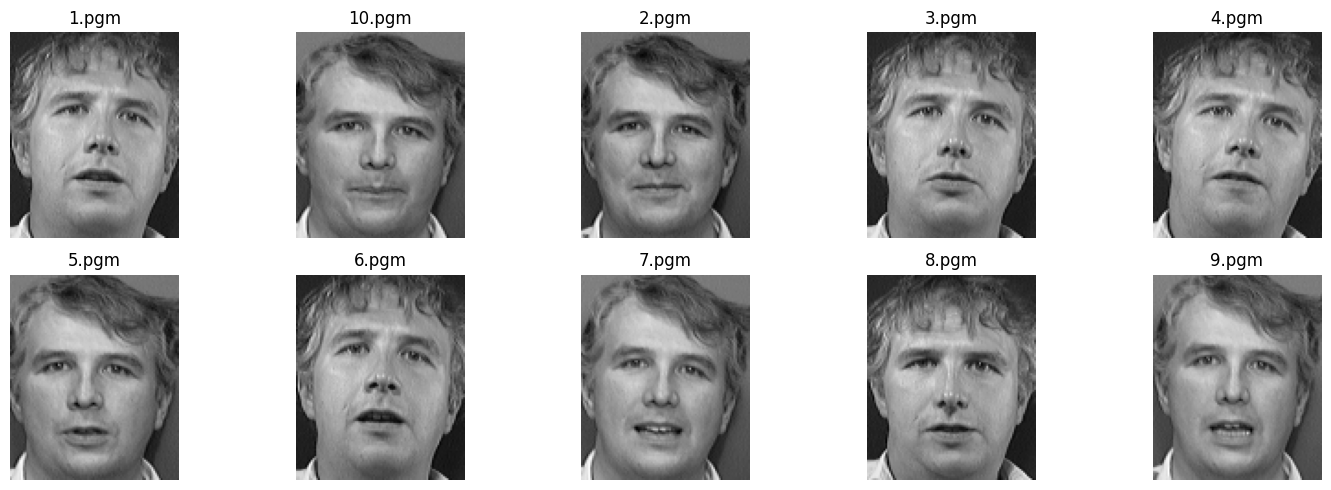

In [22]:
import os
import cv2
import matplotlib.pyplot as plt

folder = "attdb/s15"
images = sorted(os.listdir(folder))

plt.figure(figsize=(15, 5))

for i, filename in enumerate(images):
    img = cv2.imread(os.path.join(folder, filename), cv2.IMREAD_GRAYSCALE)

    plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()

Yale display all faces of a given subject

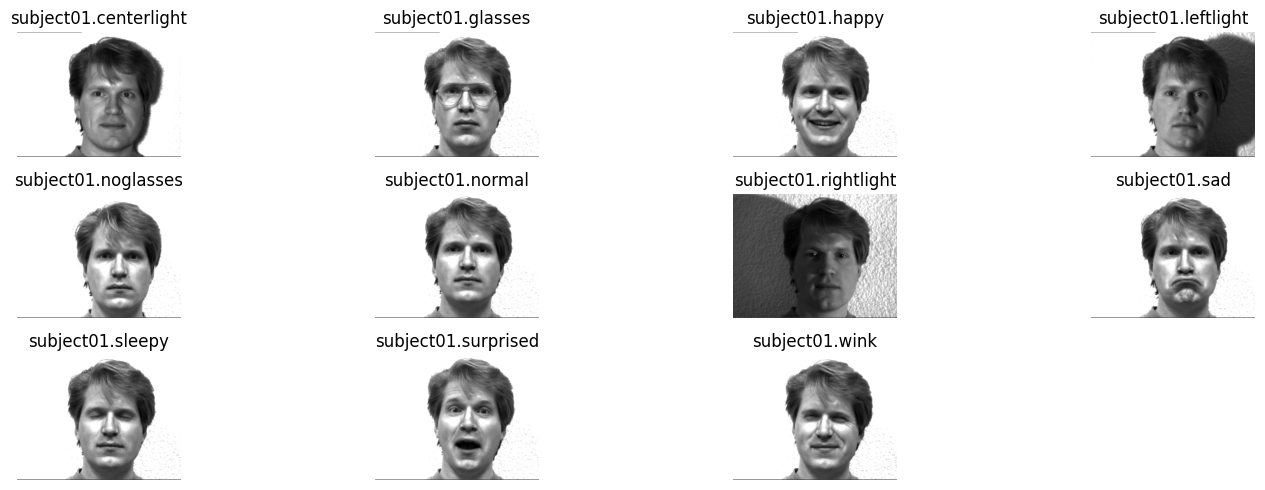

In [31]:
import os
import cv2
import matplotlib.pyplot as plt

folder = "yaledb"
subject = "subject01"

images = sorted([
    f for f in os.listdir(folder)
    if f.startswith(subject + ".")
])

plt.figure(figsize=(15, 5))

for i, filename in enumerate(images):
    img = cv2.imread(os.path.join(folder, filename), cv2.IMREAD_GRAYSCALE)

    plt.subplot(3, 4, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()